2. Time Series Analysis to determine optimal Lag and Rolling Window features 

In [ ]:
'''
Here we need to perform time series analysis to help determine the following for all ProvinceID and NOC_Grouping pair:
-Whether or not the series is Stationary of not using the Augmented Dickey-Fuller test 
-Determine  p d q and P D Q s for ARIMA, SARIMA and SARIMAX models 
-- We can use pacf and acf for this. 

We can use PACF and ACF to determine lag features
Sources:
https://medium.com/@mythrayeegopal/acf-pacf-in-time-series-a-short-explanation-81ebd9bc3fb8

'''

In [1]:
from statsmodels.tsa.stattools import pacf, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
from tqdm import tqdm

In [27]:
dp_TS = pl.scan_parquet('pre_processed_ts_data/provincial_employment_timeseries_data.parquet')

In [28]:
len(dp_TS.collect())

171186

In [29]:
df_Unique_Series = dp_TS.select(['ProvinceID','NOC_GroupingID']).unique().collect().to_pandas().sort_values(by=['ProvinceID','NOC_GroupingID'])
df_Unique_Series

,ProvinceID,NOC_GroupingID
151,10.0,1.0
452,10.0,2.0
429,10.0,4.0
241,10.0,5.0
406,10.0,6.0
...,...,...
472,59.0,55.0
125,59.0,56.0
205,59.0,57.0
3,59.0,58.0


In [25]:
df_Unique_Series['unique_id'] = df_Unique_Series.index + 1

In [26]:
#There are 554 valid time series to process, so we have to be algorithmic for Stationarity Checks. 
Unique_Series_Dict = df_Unique_Series.to_dict(orient='records')

In [8]:

Stationarity_Checks = []
Error_Checks = []
for grouping in tqdm(Unique_Series_Dict,desc='Processing Unique Series'):
    unique_id = grouping.get('unique_id',None)
    ProvinceID = grouping.get('ProvinceID',None)
    NOCGroupingID = grouping.get('NOC_GroupingID',None)

    if ProvinceID and NOCGroupingID:

        Sample = dp_TS.filter(
            (pl.col('ProvinceID')==ProvinceID)
            &(pl.col('NOC_GroupingID')==NOCGroupingID)
        ).select(['datestamp','y']).collect().to_pandas()

        Sample['datestamp'] = pd.to_datetime(Sample['datestamp'])
        Sample = Sample.sort_values(by='datestamp',ascending=True)

        ts = Sample['y']


        try:
            test_result = adfuller(ts)
            Stationarity_Checks.append({
                'unique_id':unique_id,
                'ProvinceID':ProvinceID,
                'NOC_GroupingID': NOCGroupingID,
                'ADF Statistic': test_result[0],
                'p-value': test_result[1],
                'Stationary': test_result[1] < 0.00001
            
            })
        except Exception as e:
            Error_Checks.append(
                {
                    'unique_id' : unique_id,
                    'ProvinceID': ProvinceID,
                    'NOC_GroupingID':NOCGroupingID,
                    'Error': str(e)
                }
            )

Processing Unique Series: 100%|██████████| 554/554 [00:04<00:00, 121.75it/s]


In [9]:
Error_Checks

[]

In [10]:
df_Stationarity_Checks = pd.DataFrame(Stationarity_Checks)

In [11]:
df_Stationarity_Checks

,unique_id,ProvinceID,NOC_GroupingID,ADF Statistic,p-value,Stationary
0,415,10.0,1.0,-1.993030,0.289637,False
1,279,10.0,2.0,-2.929620,0.042010,False
2,246,10.0,4.0,-3.193347,0.020373,False
3,380,10.0,5.0,-2.470269,0.122877,False
4,516,10.0,6.0,-2.937394,0.041169,False
...,...,...,...,...,...,...
549,76,59.0,55.0,-3.114655,0.025488,False
550,489,59.0,56.0,-1.819607,0.370772,False
551,99,59.0,57.0,-5.644448,0.000001,True
552,48,59.0,58.0,-1.975570,0.297387,False


In [12]:
df_Non_Unique_Id_Data = dp_TS.collect().to_pandas()
df_Unique_Id_Data = df_Non_Unique_Id_Data.merge(df_Stationarity_Checks, on=['ProvinceID','NOC_GroupingID'], how='left')
df_Unique_Id_Data

,ProvinceID,NOC_GroupingID,datestamp,Full-time employment,y,unique_id_x,unique_id_y,ADF Statistic,p-value,Stationary
0,10.0,1.0,2000-01-01,151.6,151.6,547,415,-1.99303,0.289637,False
1,10.0,1.0,2000-02-01,152.1,152.1,547,415,-1.99303,0.289637,False
2,10.0,1.0,2000-03-01,152.5,152.5,547,415,-1.99303,0.289637,False
3,10.0,1.0,2000-04-01,156.7,156.7,547,415,-1.99303,0.289637,False
4,10.0,1.0,2000-05-01,170.9,170.9,547,415,-1.99303,0.289637,False
...,...,...,...,...,...,...,...,...,...,...
171181,59.0,59.0,2025-05-01,18.3,18.3,161,255,-2.79161,0.059482,False
171182,59.0,59.0,2025-06-01,17.0,17.0,161,255,-2.79161,0.059482,False
171183,59.0,59.0,2025-07-01,15.6,15.6,161,255,-2.79161,0.059482,False
171184,59.0,59.0,2025-08-01,12.6,12.6,161,255,-2.79161,0.059482,False


In [30]:
# dp_TS_Unique_Id = pl.from_pandas(df_Unique_Id_Data)
dp_TS_Unique_Id = dp_TS.collect()

In [31]:
df_Stationary_Series = df_Stationarity_Checks[df_Stationarity_Checks['Stationary']]
df_NonStationary_Series = df_Stationarity_Checks[~df_Stationarity_Checks['Stationary']]

In [32]:
df_Stationary_Series

,unique_id,ProvinceID,NOC_GroupingID,ADF Statistic,p-value,Stationary
7,333,10.0,9.0,-6.056173,1.243645e-07,True
25,112,10.0,31.0,-7.374429,8.798239e-11,True
30,165,10.0,37.0,-5.658397,9.503488e-07,True
31,468,10.0,38.0,-5.235093,7.451796e-06,True
34,10,10.0,45.0,-5.950732,2.150338e-07,True
40,236,10.0,51.0,-7.169467,2.829241e-10,True
46,137,10.0,57.0,-7.132488,3.488559e-10,True
80,139,11.0,45.0,-5.995190,1.708237e-07,True
86,484,11.0,51.0,-6.557981,8.521139e-09,True
92,359,11.0,57.0,-7.114457,3.863153e-10,True


In [33]:
df_NonStationary_Series

,unique_id,ProvinceID,NOC_GroupingID,ADF Statistic,p-value,Stationary
0,415,10.0,1.0,-1.993030,0.289637,False
1,279,10.0,2.0,-2.929620,0.042010,False
2,246,10.0,4.0,-3.193347,0.020373,False
3,380,10.0,5.0,-2.470269,0.122877,False
4,516,10.0,6.0,-2.937394,0.041169,False
...,...,...,...,...,...,...
547,27,59.0,53.0,-4.304284,0.000437,False
549,76,59.0,55.0,-3.114655,0.025488,False
550,489,59.0,56.0,-1.819607,0.370772,False
552,48,59.0,58.0,-1.975570,0.297387,False


In [34]:
#Based on the output below, we can conclude that this series are Stationary, and we can use a simple model like ARIMA 
df_Stationary_Series['p-value'].describe()

count    4.700000e+01
mean     1.188419e-06
std      2.251167e-06
min      1.955813e-11
25%      1.378494e-09
50%      6.006867e-08
75%      8.384782e-07
max      8.825520e-06
Name: p-value, dtype: float64

In [35]:
# All Stats are well over 0.05, indicating non-stationarity 
df_NonStationary_Series['p-value'].describe()

count    506.000000
mean       0.438313
std        0.361372
min        0.000015
25%        0.054909
50%        0.384100
75%        0.780037
max        0.998779
Name: p-value, dtype: float64

Using ACF and PACF to Determine if Stationary sets are actualy stationary

In [36]:
df_Stationary_Series

,unique_id,ProvinceID,NOC_GroupingID,ADF Statistic,p-value,Stationary
7,333,10.0,9.0,-6.056173,1.243645e-07,True
25,112,10.0,31.0,-7.374429,8.798239e-11,True
30,165,10.0,37.0,-5.658397,9.503488e-07,True
31,468,10.0,38.0,-5.235093,7.451796e-06,True
34,10,10.0,45.0,-5.950732,2.150338e-07,True
40,236,10.0,51.0,-7.169467,2.829241e-10,True
46,137,10.0,57.0,-7.132488,3.488559e-10,True
80,139,11.0,45.0,-5.995190,1.708237e-07,True
86,484,11.0,51.0,-6.557981,8.521139e-09,True
92,359,11.0,57.0,-7.114457,3.863153e-10,True


In [37]:
Sample = dp_TS_Unique_Id.filter(
    pl.col('unique_id') == 81
).select(['datestamp','y']).to_pandas().sort_values(by='datestamp', ascending=True)


Sample['datestamp'] = pd.to_datetime(Sample['datestamp'])

Sample = Sample.sort_values('datestamp')

ts = Sample.set_index('datestamp')['y'].dropna()

In [38]:
max_lag = 48
acf_vals = acf(ts, nlags=max_lag)
pacf_vals = pacf(ts, nlags=max_lag)

In [39]:
for lag in range(len(acf_vals)):
    print(f"Lag {lag}: ACF={acf_vals[lag]:.3f}, PACF={pacf_vals[lag]:.3f}")

Lag 0: ACF=1.000, PACF=1.000
Lag 1: ACF=0.709, PACF=0.711
Lag 2: ACF=0.499, PACF=-0.006
Lag 3: ACF=0.298, PACF=-0.110
Lag 4: ACF=0.121, PACF=-0.103
Lag 5: ACF=0.027, PACF=0.017
Lag 6: ACF=-0.009, PACF=0.039
Lag 7: ACF=0.016, PACF=0.080
Lag 8: ACF=0.094, PACF=0.122
Lag 9: ACF=0.177, PACF=0.090
Lag 10: ACF=0.224, PACF=0.025
Lag 11: ACF=0.278, PACF=0.107
Lag 12: ACF=0.268, PACF=0.004
Lag 13: ACF=0.196, PACF=-0.070
Lag 14: ACF=0.155, PACF=0.063
Lag 15: ACF=0.097, PACF=0.003
Lag 16: ACF=0.033, PACF=-0.049
Lag 17: ACF=0.025, PACF=0.047
Lag 18: ACF=0.012, PACF=-0.023
Lag 19: ACF=0.049, PACF=0.056
Lag 20: ACF=0.174, PACF=0.216
Lag 21: ACF=0.210, PACF=-0.041
Lag 22: ACF=0.250, PACF=0.035
Lag 23: ACF=0.294, PACF=0.114
Lag 24: ACF=0.243, PACF=-0.057
Lag 25: ACF=0.191, PACF=0.003
Lag 26: ACF=0.116, PACF=-0.024
Lag 27: ACF=0.055, PACF=0.021
Lag 28: ACF=0.042, PACF=0.048
Lag 29: ACF=0.065, PACF=0.061
Lag 30: ACF=0.080, PACF=-0.007
Lag 31: ACF=0.120, PACF=-0.010
Lag 32: ACF=0.153, PACF=0.003
Lag 33: 

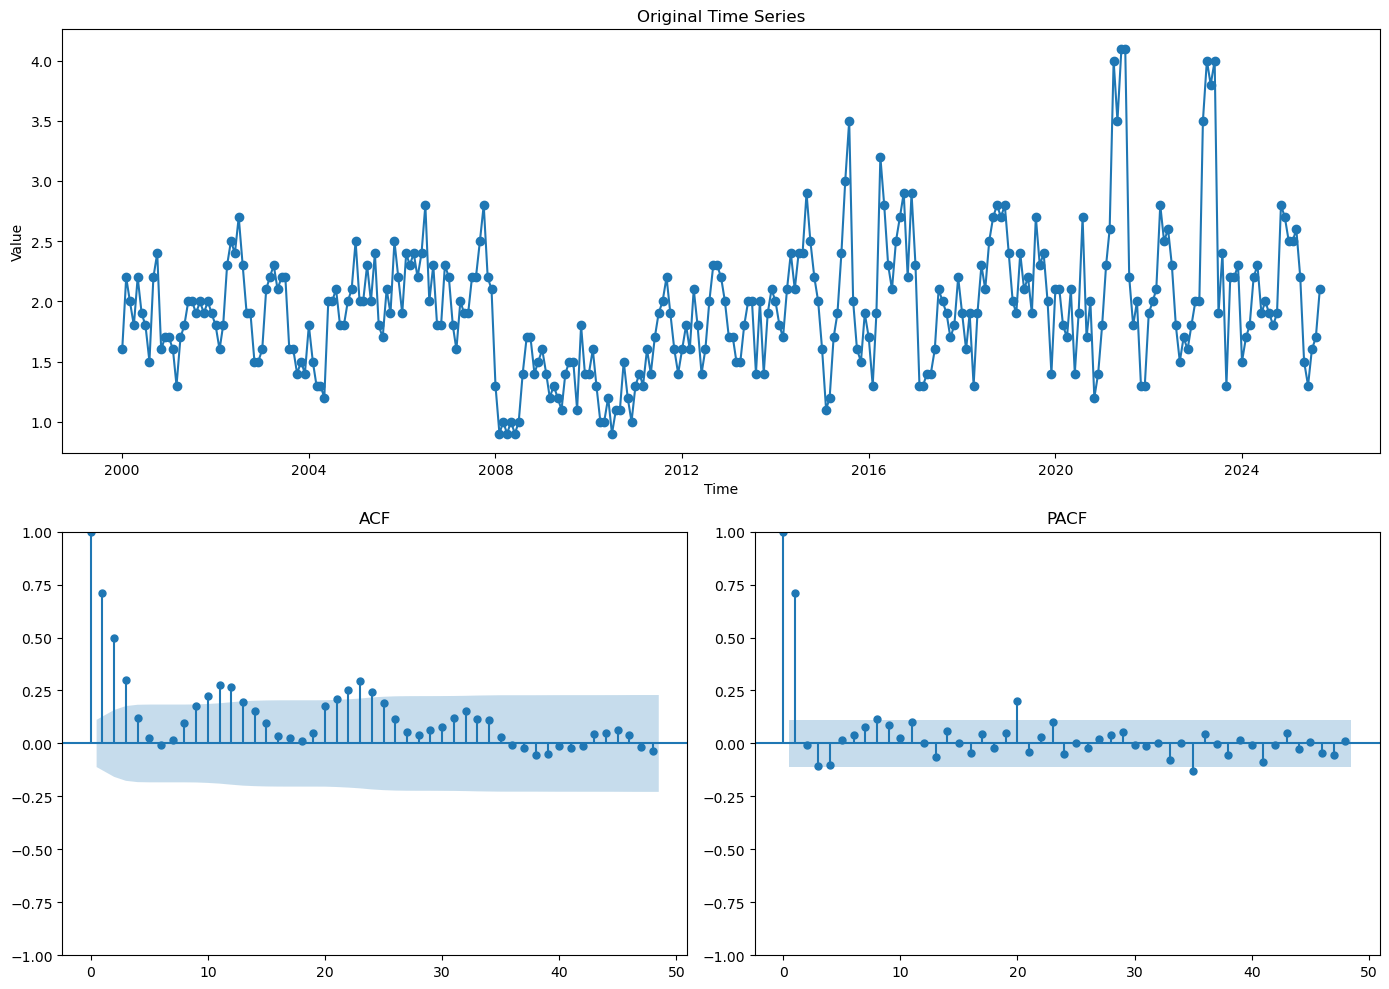

In [40]:
fig = plt.figure(figsize=(14, 10))

# Original series (row 1, full width)
ax1 = plt.subplot2grid((2,2), (0,0), colspan=2)
ax1.plot(ts, marker='o')
ax1.set_title("Original Time Series")
ax1.set_xlabel("Time")
ax1.set_ylabel("Value")

# ACF (row 2, col 0)
ax2 = plt.subplot2grid((2,2), (1,0))
plot_acf(ts, lags=max_lag, ax=ax2)
ax2.set_title("ACF")

# PACF (row 2, col 1)
ax3 = plt.subplot2grid((2,2), (1,1))
plot_pacf(ts, lags=max_lag, ax=ax3)
ax3.set_title("PACF")

plt.tight_layout()
plt.show()

Checking Non Stationary Sets with ACF and PACF 

In [41]:
df_NonStationary_Series

,unique_id,ProvinceID,NOC_GroupingID,ADF Statistic,p-value,Stationary
0,415,10.0,1.0,-1.993030,0.289637,False
1,279,10.0,2.0,-2.929620,0.042010,False
2,246,10.0,4.0,-3.193347,0.020373,False
3,380,10.0,5.0,-2.470269,0.122877,False
4,516,10.0,6.0,-2.937394,0.041169,False
...,...,...,...,...,...,...
547,27,59.0,53.0,-4.304284,0.000437,False
549,76,59.0,55.0,-3.114655,0.025488,False
550,489,59.0,56.0,-1.819607,0.370772,False
552,48,59.0,58.0,-1.975570,0.297387,False


In [42]:
Sample = dp_TS_Unique_Id.filter(
    pl.col('unique_id') == 301
).select(['datestamp','y']).to_pandas().sort_values(by='datestamp', ascending=True)


Sample['datestamp'] = pd.to_datetime(Sample['datestamp'])

Sample = Sample.sort_values('datestamp')

ts = Sample.set_index('datestamp')['y'].dropna()

In [43]:
max_lag = 48
acf_vals = acf(ts, nlags=max_lag)
pacf_vals = pacf(ts, nlags=max_lag)

In [44]:
for lag in range(len(acf_vals)):
    print(f"Lag {lag}: ACF={acf_vals[lag]:.3f}, PACF={pacf_vals[lag]:.3f}")

Lag 0: ACF=1.000, PACF=1.000
Lag 1: ACF=0.911, PACF=0.914
Lag 2: ACF=0.850, PACF=0.121
Lag 3: ACF=0.791, PACF=0.005
Lag 4: ACF=0.735, PACF=-0.012
Lag 5: ACF=0.675, PACF=-0.046
Lag 6: ACF=0.617, PACF=-0.037
Lag 7: ACF=0.599, PACF=0.225
Lag 8: ACF=0.590, PACF=0.116
Lag 9: ACF=0.580, PACF=0.034
Lag 10: ACF=0.585, PACF=0.109
Lag 11: ACF=0.587, PACF=0.012
Lag 12: ACF=0.598, PACF=0.071
Lag 13: ACF=0.600, PACF=0.044
Lag 14: ACF=0.593, PACF=-0.004
Lag 15: ACF=0.579, PACF=-0.044
Lag 16: ACF=0.566, PACF=0.046
Lag 17: ACF=0.556, PACF=0.049
Lag 18: ACF=0.538, PACF=-0.002
Lag 19: ACF=0.517, PACF=-0.021
Lag 20: ACF=0.501, PACF=-0.002
Lag 21: ACF=0.505, PACF=0.122
Lag 22: ACF=0.505, PACF=0.028
Lag 23: ACF=0.506, PACF=0.038
Lag 24: ACF=0.511, PACF=0.017
Lag 25: ACF=0.526, PACF=0.078
Lag 26: ACF=0.539, PACF=0.049
Lag 27: ACF=0.549, PACF=0.072
Lag 28: ACF=0.538, PACF=-0.107
Lag 29: ACF=0.523, PACF=-0.062
Lag 30: ACF=0.494, PACF=-0.105
Lag 31: ACF=0.461, PACF=-0.048
Lag 32: ACF=0.426, PACF=-0.005
Lag 33:

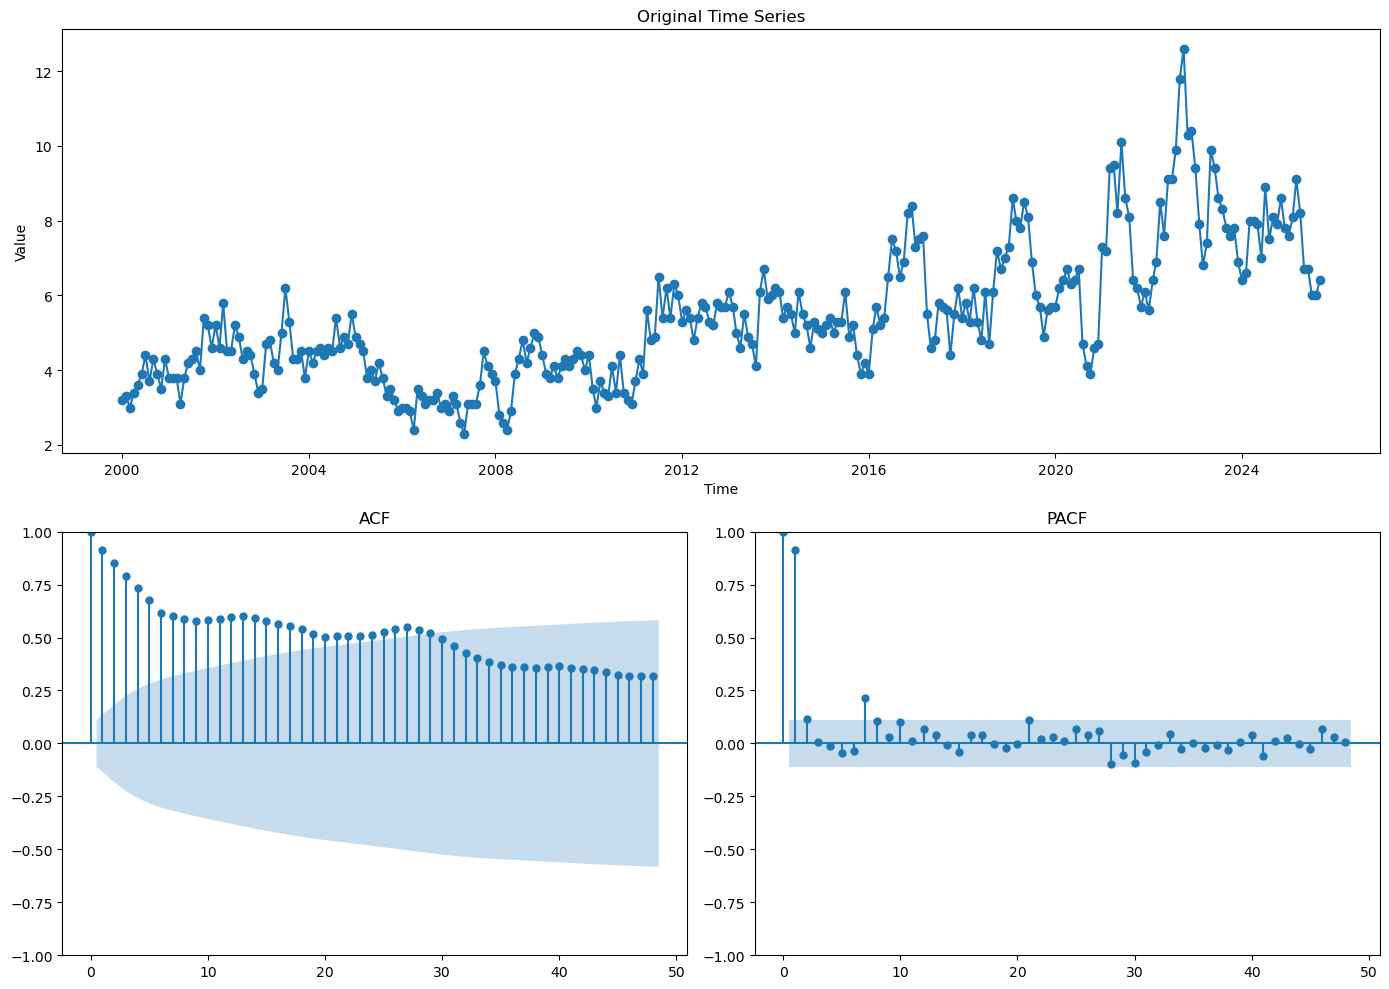

In [45]:
fig = plt.figure(figsize=(14, 10))

# Original series (row 1, full width)
ax1 = plt.subplot2grid((2,2), (0,0), colspan=2)
ax1.plot(ts, marker='o')
ax1.set_title("Original Time Series")
ax1.set_xlabel("Time")
ax1.set_ylabel("Value")

# ACF (row 2, col 0)
ax2 = plt.subplot2grid((2,2), (1,0))
plot_acf(ts, lags=max_lag, ax=ax2)
ax2.set_title("ACF")

# PACF (row 2, col 1)
ax3 = plt.subplot2grid((2,2), (1,1))
plot_pacf(ts, lags=max_lag, ax=ax3)
ax3.set_title("PACF")

plt.tight_layout()
plt.show()

In [46]:
df_Unique_Id_Data = dp_TS_Unique_Id.to_pandas()

In [48]:
df_Unique_Id_Data

,ProvinceID,NOC_GroupingID,datestamp,Full-time employment,y,unique_id
0,10.0,1.0,2000-01-01,151.6,151.6,547
1,10.0,1.0,2000-02-01,152.1,152.1,547
2,10.0,1.0,2000-03-01,152.5,152.5,547
3,10.0,1.0,2000-04-01,156.7,156.7,547
4,10.0,1.0,2000-05-01,170.9,170.9,547
...,...,...,...,...,...,...
171181,59.0,59.0,2025-05-01,18.3,18.3,161
171182,59.0,59.0,2025-06-01,17.0,17.0,161
171183,59.0,59.0,2025-07-01,15.6,15.6,161
171184,59.0,59.0,2025-08-01,12.6,12.6,161


In [49]:
#Generating Exogenous Features 
df_Unique_Id_Data['datestamp'] = pd.to_datetime(df_Unique_Id_Data['datestamp'])

# Month and quarter
df_Unique_Id_Data['month'] = df_Unique_Id_Data['datestamp'].dt.month        # 1-12
df_Unique_Id_Data['quarter'] = df_Unique_Id_Data['datestamp'].dt.quarter    # 1-4

# Month within quarter: 1,2,3
df_Unique_Id_Data['month_in_quarter'] = ((df_Unique_Id_Data['month'] - 1) % 3) + 1

# Optional: cyclic encoding for month_in_quarter
df_Unique_Id_Data['month_in_quarter_sin'] = np.sin(2 * np.pi * df_Unique_Id_Data['month_in_quarter'] / 3)
df_Unique_Id_Data['month_in_quarter_cos'] = np.cos(2 * np.pi * df_Unique_Id_Data['month_in_quarter'] / 3)

# Cyclical encoding for month (for full year seasonality)
df_Unique_Id_Data['month_sin'] = np.sin(2 * np.pi * df_Unique_Id_Data['month'] / 12)
df_Unique_Id_Data['month_cos'] = np.cos(2 * np.pi * df_Unique_Id_Data['month'] / 12)

# Cyclical encoding for quarter (for quarterly seasonality)
df_Unique_Id_Data['quarter_sin'] = np.sin(2 * np.pi * df_Unique_Id_Data['quarter'] / 4)
df_Unique_Id_Data['quarter_cos'] = np.cos(2 * np.pi * df_Unique_Id_Data['quarter'] / 4)

df_Unique_Id_Data['week'] = df_Unique_Id_Data['datestamp'].dt.isocalendar().week.astype(int)


df_Unique_Id_Data['week_sin'] = np.sin(2 * np.pi * df_Unique_Id_Data['week'] / 52)
df_Unique_Id_Data['week_cos'] = np.cos(2 * np.pi * df_Unique_Id_Data['week'] / 52)




In [53]:
df_Unique_Id_Data

,ProvinceID,NOC_GroupingID,datestamp,Full-time employment,y,unique_id,month,quarter,month_in_quarter,month_in_quarter_sin,month_in_quarter_cos,month_sin,month_cos,quarter_sin,quarter_cos,week,week_sin,week_cos
0,10.0,1.0,2000-01-01,151.6,151.6,547,1,1,1,8.660254e-01,-0.5,5.000000e-01,8.660254e-01,1.000000e+00,6.123234e-17,52,6.432491e-16,1.000000e+00
1,10.0,1.0,2000-02-01,152.1,152.1,547,2,1,2,-8.660254e-01,-0.5,8.660254e-01,5.000000e-01,1.000000e+00,6.123234e-17,5,5.680647e-01,8.229839e-01
2,10.0,1.0,2000-03-01,152.5,152.5,547,3,1,3,-2.449294e-16,1.0,1.000000e+00,6.123234e-17,1.000000e+00,6.123234e-17,9,8.854560e-01,4.647232e-01
3,10.0,1.0,2000-04-01,156.7,156.7,547,4,2,1,8.660254e-01,-0.5,8.660254e-01,-5.000000e-01,1.224647e-16,-1.000000e+00,13,1.000000e+00,-1.608123e-16
4,10.0,1.0,2000-05-01,170.9,170.9,547,5,2,2,-8.660254e-01,-0.5,5.000000e-01,-8.660254e-01,1.224647e-16,-1.000000e+00,18,8.229839e-01,-5.680647e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171181,59.0,59.0,2025-05-01,18.3,18.3,161,5,2,2,-8.660254e-01,-0.5,5.000000e-01,-8.660254e-01,1.224647e-16,-1.000000e+00,18,8.229839e-01,-5.680647e-01
171182,59.0,59.0,2025-06-01,17.0,17.0,161,6,2,3,-2.449294e-16,1.0,1.224647e-16,-1.000000e+00,1.224647e-16,-1.000000e+00,22,4.647232e-01,-8.854560e-01
171183,59.0,59.0,2025-07-01,15.6,15.6,161,7,3,1,8.660254e-01,-0.5,-5.000000e-01,-8.660254e-01,-1.000000e+00,-1.836970e-16,27,-1.205367e-01,-9.927089e-01
171184,59.0,59.0,2025-08-01,12.6,12.6,161,8,3,2,-8.660254e-01,-0.5,-8.660254e-01,-5.000000e-01,-1.000000e+00,-1.836970e-16,31,-5.680647e-01,-8.229839e-01


In [54]:
df_Unique_Id_Data.to_parquet('pre_processed_ts_data/forecasting-data-set.parquet',index=False)

In [58]:
df_Unique_Id_Data.columns

Index(['ProvinceID', 'NOC_GroupingID', 'datestamp', 'Full-time employment',
       'y', 'unique_id', 'month', 'quarter', 'month_in_quarter',
       'month_in_quarter_sin', 'month_in_quarter_cos', 'month_sin',
       'month_cos', 'quarter_sin', 'quarter_cos', 'week', 'week_sin',
       'week_cos'],
      dtype='object')

In [1]:
import pandas as pd 

In [ ]:
df = pd.read_parquet('pre_processed_ts_data/forecasting-data-set.parquet')